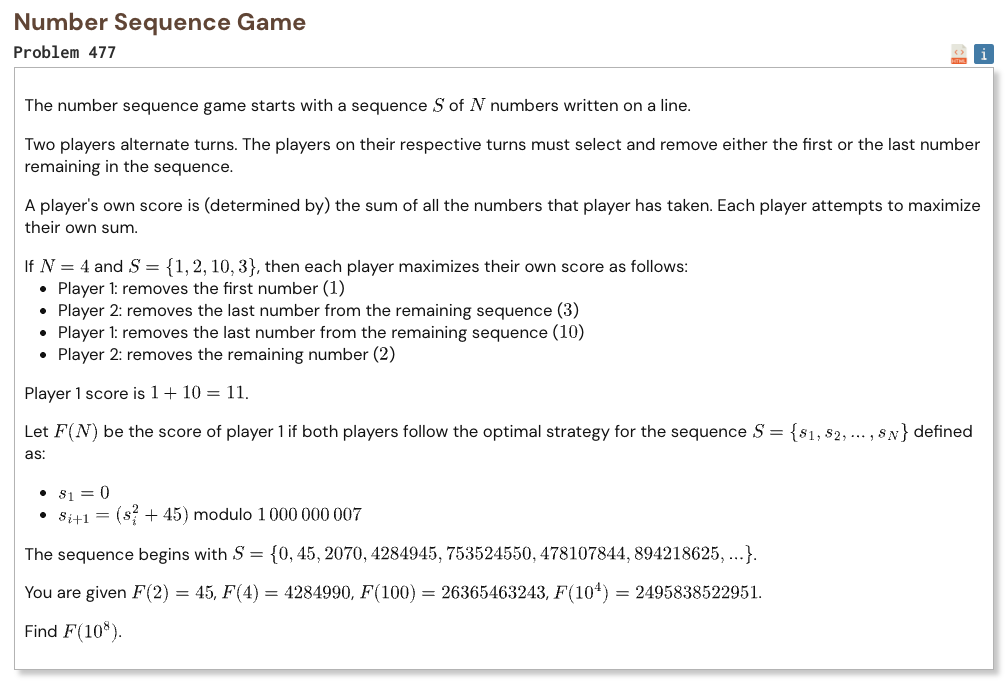

## Initial approach

- rewrite the game using the score difference between the current player and the opponent
- whenever three consecutive values have a local maximum in the middle, replace the three values by one equivalent value
- keep applying this reduction with a stack until the remaining sequence has no local peaks
- the reduced sequence has a simple valley shape, so repeatedly taking the larger end gives the optimal score difference
- combine that difference with the total sum to recover player 1's score
- generate the modular sequence only until a value repeats because after that the sequence becomes periodic
- evaluate one aligned cycle block and use its constant score increase to jump directly to 10^8
- no external library is needed

In [1]:
%%time

def compute_score(seq):
    stack = []
    total_sum = 0

    for value in seq:
        total_sum += value
        stack.append(value)

        while len(stack) >= 3:
            a = stack[-3]
            b = stack[-2]
            c = stack[-1]

            if b < a or b < c:
                break

            stack[-3] = a - b + c
            stack.pop()
            stack.pop()

    delta = 0
    left = 0
    right = len(stack) - 1
    sign = 1

    while left <= right:
        if stack[left] > stack[right]:
            delta += sign * stack[left]
            left += 1
        else:
            delta += sign * stack[right]
            right -= 1

        sign = -sign

    return (total_sum + delta) // 2


def solve(n):
    mod = 1_000_000_007

    seen = {}
    sequence = []

    value = 0

    while len(sequence) < n:
        if value in seen:
            cycle_start = seen[value]
            cycle_length = len(sequence) - cycle_start
            break

        seen[value] = len(sequence)
        sequence.append(value)
        value = (value * value + 45) % mod
    else:
        return compute_score(sequence)

    remainder = (n - cycle_start) % cycle_length

    first = (
        sequence[:cycle_start]
        + sequence[
            cycle_start:
            cycle_start + remainder
        ]
    )

    cycle = (
        sequence[
            cycle_start + remainder:
            cycle_start + cycle_length
        ]
        + sequence[
            cycle_start:
            cycle_start + remainder
        ]
    )

    score_first = compute_score(first)
    score_with_cycle = compute_score(first + cycle)

    blocks = (n - len(first)) // len(cycle)

    return (
        score_first
        + blocks * (
            score_with_cycle - score_first
        )
    )


result = solve(100_000_000)

print("Result:", result)

Result: 25044905874565165
CPU times: user 39.9 ms, sys: 3.31 ms, total: 43.2 ms
Wall time: 51 ms
